Use SHAP (SHapley Additive exPlanations) values to explain complex model predictions at both global and local levels, interpreting feature contributions and interaction effects for transparency and accountability.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 1000

In [4]:
age = np.random.normal(62, 12, n_samples).clip(25, 90).round(1)
bmi = np.random.normal(28.5, 5.0, n_samples).clip(17.0, 45.0).round(1)
systolic_bp = np.random.normal(135, 18, n_samples).clip(90, 200).round(1)
troponin_level = np.random.exponential(scale=0.4, size=n_samples).clip(0.01, 5.0).round(3)
creatinine = np.random.normal(1.1, 0.4, n_samples).clip(0.4, 4.0).round(2)
glucose = np.random.normal(110, 30, n_samples).clip(70, 300).round(1)

In [5]:
logits = (
    -4.5
    + 0.04 * (age - 60)
    + 0.05 * (bmi - 25)
    + 0.02 * (systolic_bp - 120)
    + 2.20 * troponin_level
    + 0.80 * (creatinine ** 2)
    + 0.015 * (glucose - 100)
    + 0.03 * (troponin_level * age)  # Interaction Effect
)

In [6]:
probs = 1 / (1 + np.exp(-logits))
cardiac_event = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [7]:
df_shap = pd.DataFrame({
    'age': age,
    'bmi': bmi,
    'systolic_bp': systolic_bp,
    'troponin_level': troponin_level,
    'creatinine': creatinine,
    'glucose': glucose,
    'cardiac_event': cardiac_event
})

In [8]:
print("Dataset Shape:", df_shap.shape)
print("Cardiac Event Target Rate:\n", df_shap['cardiac_event'].value_counts(normalize=True).round(3))

Dataset Shape: (1000, 7)
Cardiac Event Target Rate:
 cardiac_event
0    0.688
1    0.312
Name: proportion, dtype: float64


In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score

In [12]:
X = df_shap.drop(columns=['cardiac_event'])
y = df_shap['cardiac_event']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [14]:
model = HistGradientBoostingClassifier(max_iter=150, random_state=42)
model.fit(X_train, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

HistGradientBoostingClassifier(max_iter=150, random_state=42)

In [15]:
auc_score = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"Model Out-of-Sample ROC-AUC Score: {auc_score:.4f}")

Model Out-of-Sample ROC-AUC Score: 0.8195


In [16]:
perm_importance = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)

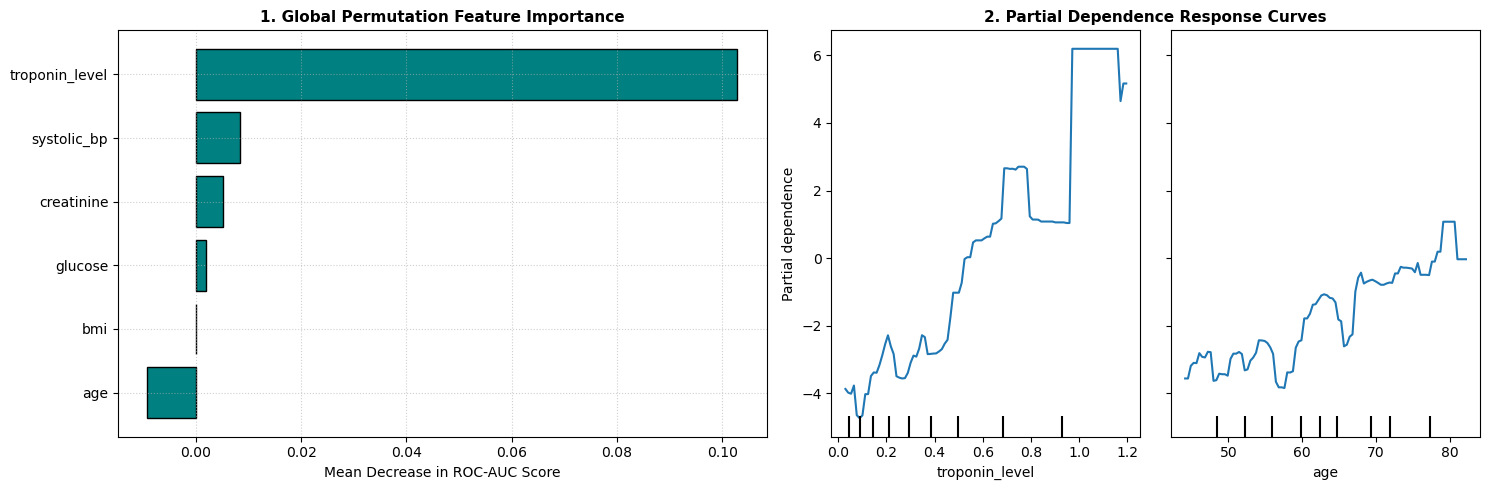

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sorted_idx = perm_importance.importances_mean.argsort()
axes[0].barh(X.columns[sorted_idx], perm_importance.importances_mean[sorted_idx], color='teal', edgecolor='black')
axes[0].set_title("1. Global Permutation Feature Importance", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Mean Decrease in ROC-AUC Score")
axes[0].grid(True, linestyle=':', alpha=0.6)
PartialDependenceDisplay.from_estimator(
    model, 
    X_test, 
    features=['troponin_level', 'age'], 
    ax=axes[1]
)
axes[1].set_title("2. Partial Dependence Response Curves", fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()